# PLAYSTORE DATASET ANALYSIS

Performed data cleaning, missing value handling, outlier detection, exploratory data analysis, and visualization on the Playstore dataset using Pandas, Matplotlib, and Seaborn.

## Loading Dataset into Python Environment

Imported Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
play_data=pd.read_csv(r"C:\Users\LENOVO\Desktop\Unique Occassio\DataSets\google_play_apps_2026_sample.csv")

Displayed the top 5 rows of the data

In [3]:
play_data.head()

,app_id,title,developer,developer_domain,genre,is_game,installs,score,ratings,reviews,free,price,currency,contains_ads,offers_iap,content_rating,released,last_updated,fliar_profile_url
0,com.facebook.katana,Facebook,"Meta Platforms, Inc.",facebook.com,Social,False,"10,000,000,000+",4.56,182075532.0,4251426.0,True,0.0,USD,True,True,Teen,NaN,2026-06-03,https://fliarbi.com/company/facebook/1dxlnk4j2...
1,com.facebook.orca,Messenger,"Meta Platforms, Inc.",facebook.com,Communication,False,"5,000,000,000+",4.72,112112364.0,2463383.0,True,0.0,USD,False,True,Everyone,2014-01-30,2026-06-01,https://fliarbi.com/company/facebook/1dxlnk4j2...
2,com.facebook.lite,Facebook Lite,"Meta Platforms, Inc.",facebook.com,Social,False,"1,000,000,000+",4.52,37191569.0,136089.0,True,0.0,USD,True,True,Teen,2018-03-15,2026-06-02,https://fliarbi.com/company/facebook/1dxlnk4j2...
3,com.twitter.android,X,X Corp.,twitter.com,News & Magazines,False,"1,000,000,000+",3.62,22991633.0,786522.0,True,0.0,USD,True,True,Mature 17+,2010-04-30,2026-06-05,https://fliarbi.com/company/fabula/k7j9a78ffq/...
4,flipboard.boxer.app,Briefing,Flipboard,flipboard.com,News & Magazines,False,"1,000,000,000+",3.15,751558.0,42003.0,True,0.0,USD,True,False,Teen,2015-05-13,2026-03-09,https://fliarbi.com/company/flipboard/2x8224kv...


Shape of the data

In [4]:
play_data.shape

(100013, 19)

Statistical summary of data

In [5]:
play_data.describe().T

,count,mean,std,min,25%,50%,75%,max
score,31755.0,4.031244,7.602799e-01,1.0,3.67,4.22,4.58,5.000000e+00
ratings,31755.0,34187.683672,1.253892e+06,5.0,101.00,465.00,2903.50,1.820755e+08
reviews,31755.0,912.197859,2.999251e+04,0.0,4.00,12.00,59.00,4.251426e+06
price,100000.0,0.067083,1.643609e+00,0.0,0.00,0.00,0.00,2.949900e+02


Information about the data

In [6]:
play_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100013 entries, 0 to 100012
Data columns (total 19 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   app_id             100013 non-null  str    
 1   title              100013 non-null  str    
 2   developer          100013 non-null  str    
 3   developer_domain   63527 non-null   str    
 4   genre              100013 non-null  str    
 5   is_game            100013 non-null  bool   
 6   installs           100013 non-null  str    
 7   score              31755 non-null   float64
 8   ratings            31755 non-null   float64
 9   reviews            31755 non-null   float64
 10  free               100013 non-null  bool   
 11  price              100000 non-null  float64
 12  currency           100013 non-null  str    
 13  contains_ads       100013 non-null  bool   
 14  offers_iap         100013 non-null  bool   
 15  content_rating     100013 non-null  str    
 16  released     

Found the number of unique values of each column

In [7]:
play_data.nunique()

app_id               100013
title                 98999
developer             37480
developer_domain      36964
genre                    48
is_game                   2
installs                 15
score                   386
ratings                9617
reviews                2393
free                      2
price                    80
currency                  1
contains_ads              2
offers_iap                2
content_rating            5
released               5611
last_updated           3517
fliar_profile_url     15844
dtype: int64

Displayed the unique values in each column

In [8]:
for i in play_data.columns:
    print(i)
    print(play_data[i].unique())
    print("-"*50)
    print("\n")

app_id
<ArrowStringArray>
[               'com.facebook.katana',                  'com.facebook.orca',
                  'com.facebook.lite',                'com.twitter.android',
                'flipboard.boxer.app',                   'com.rlk.weathers',
             'com.transsion.carlcare',         'com.transsion.filemanagerx',
              'com.contextlogic.wish',                    'com.phonepe.app',
 ...
      'za.org.trees.mobile.footprint',               'za.thumamina.userapp',
            'zasoft.com.zaposcloudvn',                 'zenplus.loylap.app',
      'zeroinfinity.space.cloudegyan', 'zeroinfinity.space.hindifunnyjokes',
                'zip.gigantino.autem',             'zm.unza.unzastudentapp',
                 'zoo.ticket.eticket',                  'zundel.ag.letters']
Length: 100013, dtype: str
--------------------------------------------------


title
<ArrowStringArray>
[                      'Facebook',                      'Messenger',
                  'Facebo

## Missing Values

Checking for null values

In [9]:
play_data.isna().sum()

app_id                   0
title                    0
developer                0
developer_domain     36486
genre                    0
is_game                  0
installs                 0
score                68258
ratings              68258
reviews              68258
free                     0
price                   13
currency                 0
contains_ads             0
offers_iap               0
content_rating           0
released             17467
last_updated             0
fliar_profile_url    69638
dtype: int64

Droping the unwanted columns with large amount of missing values

In [10]:
play_data.drop(['developer_domain'], axis=1, inplace=True)

The missing values in score, ratings and reviews occur in exactly the same 68,258 records.More than 68% of the scores are missing, and imputing them would create artificial ratings that could significantly distort your analysis.created a separate subset for rating analysis.

In [11]:
# Create a separate dataset containing apps with available ratings
rated_data = play_data.dropna(subset=['score']).copy()

In [12]:
rated_data.isna().sum()

app_id                   0
title                    0
developer                0
genre                    0
is_game                  0
installs                 0
score                    0
ratings                  0
reviews                  0
free                     0
price                    0
currency                 0
contains_ads             0
offers_iap               0
content_rating           0
released               331
last_updated             0
fliar_profile_url    18999
dtype: int64

Drop both unwanted columns with missing data

In [13]:
rated_data.drop(['released','fliar_profile_url'], axis=1, inplace=True)

Again checking the null values

In [14]:
rated_data.isna().sum()

app_id            0
title             0
developer         0
genre             0
is_game           0
installs          0
score             0
ratings           0
reviews           0
free              0
price             0
currency          0
contains_ads      0
offers_iap        0
content_rating    0
last_updated      0
dtype: int64

### Successfully handled all the null values

## Correlaton Matrix

<Axes: >

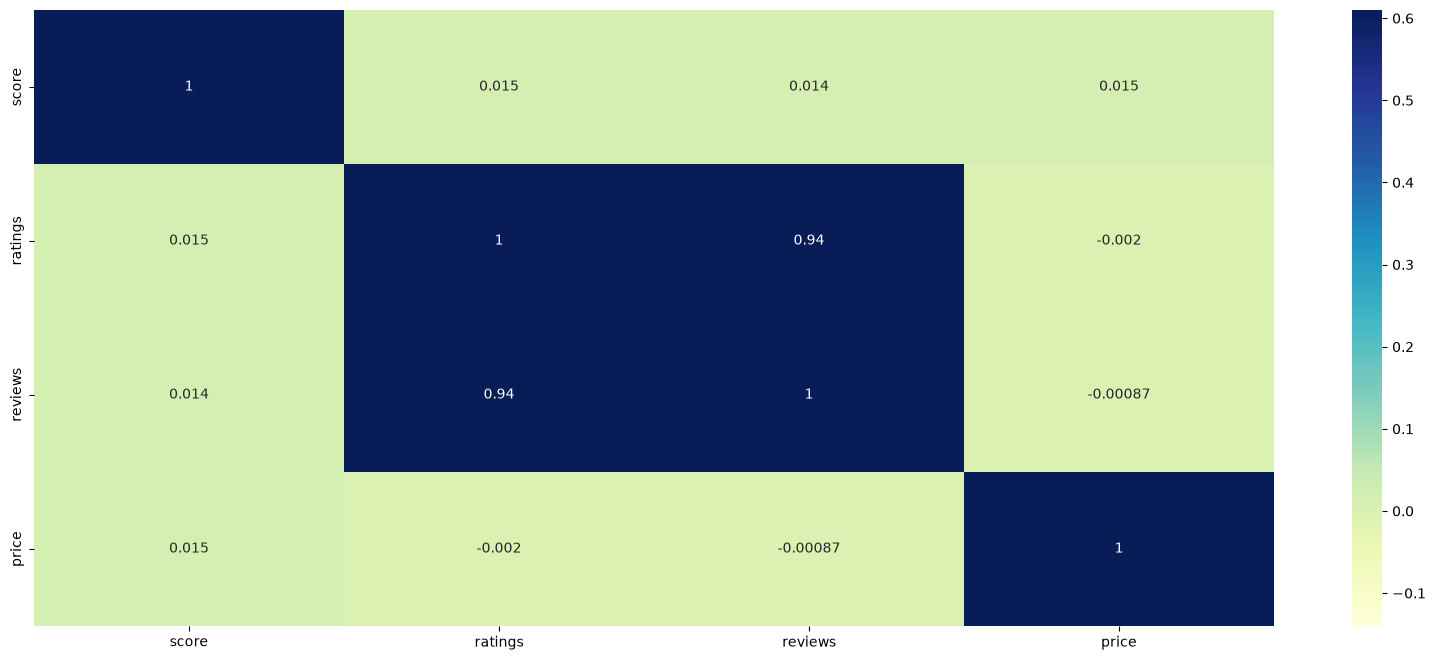

In [15]:
# Select numerical columns
numeric_data = rated_data.select_dtypes(include='number')

# Correlaton Matrix
corrmatrix=numeric_data.corr()
plt.subplots(figsize=(20,8))
sns.heatmap(corrmatrix,annot=True,vmin=-0.14,vmax=0.61,cmap='YlGnBu')

## Feature Engineering

Dropping irrelevent Columns

In [16]:
rated_data.drop(['app_id','title','currency'], axis=1, inplace=True)

Created one additional column to measure how many calendar years have passed since the last update.

In [17]:
rated_data['last_updated'] = pd.to_datetime(
    rated_data['last_updated']
)

In [18]:
rated_data['App Update Age'] = (
    pd.Timestamp.today().year -
    rated_data['last_updated'].dt.year
)

In [19]:
rated_data.head()

,developer,genre,is_game,installs,score,ratings,reviews,free,price,contains_ads,offers_iap,content_rating,last_updated,App Update Age
0,"Meta Platforms, Inc.",Social,False,"10,000,000,000+",4.56,182075532.0,4251426.0,True,0.0,True,True,Teen,2026-06-03,0
1,"Meta Platforms, Inc.",Communication,False,"5,000,000,000+",4.72,112112364.0,2463383.0,True,0.0,False,True,Everyone,2026-06-01,0
2,"Meta Platforms, Inc.",Social,False,"1,000,000,000+",4.52,37191569.0,136089.0,True,0.0,True,True,Teen,2026-06-02,0
3,X Corp.,News & Magazines,False,"1,000,000,000+",3.62,22991633.0,786522.0,True,0.0,True,True,Mature 17+,2026-06-05,0
4,Flipboard,News & Magazines,False,"1,000,000,000+",3.15,751558.0,42003.0,True,0.0,True,False,Teen,2026-03-09,0


## Outlier Handling

Checking Outliers

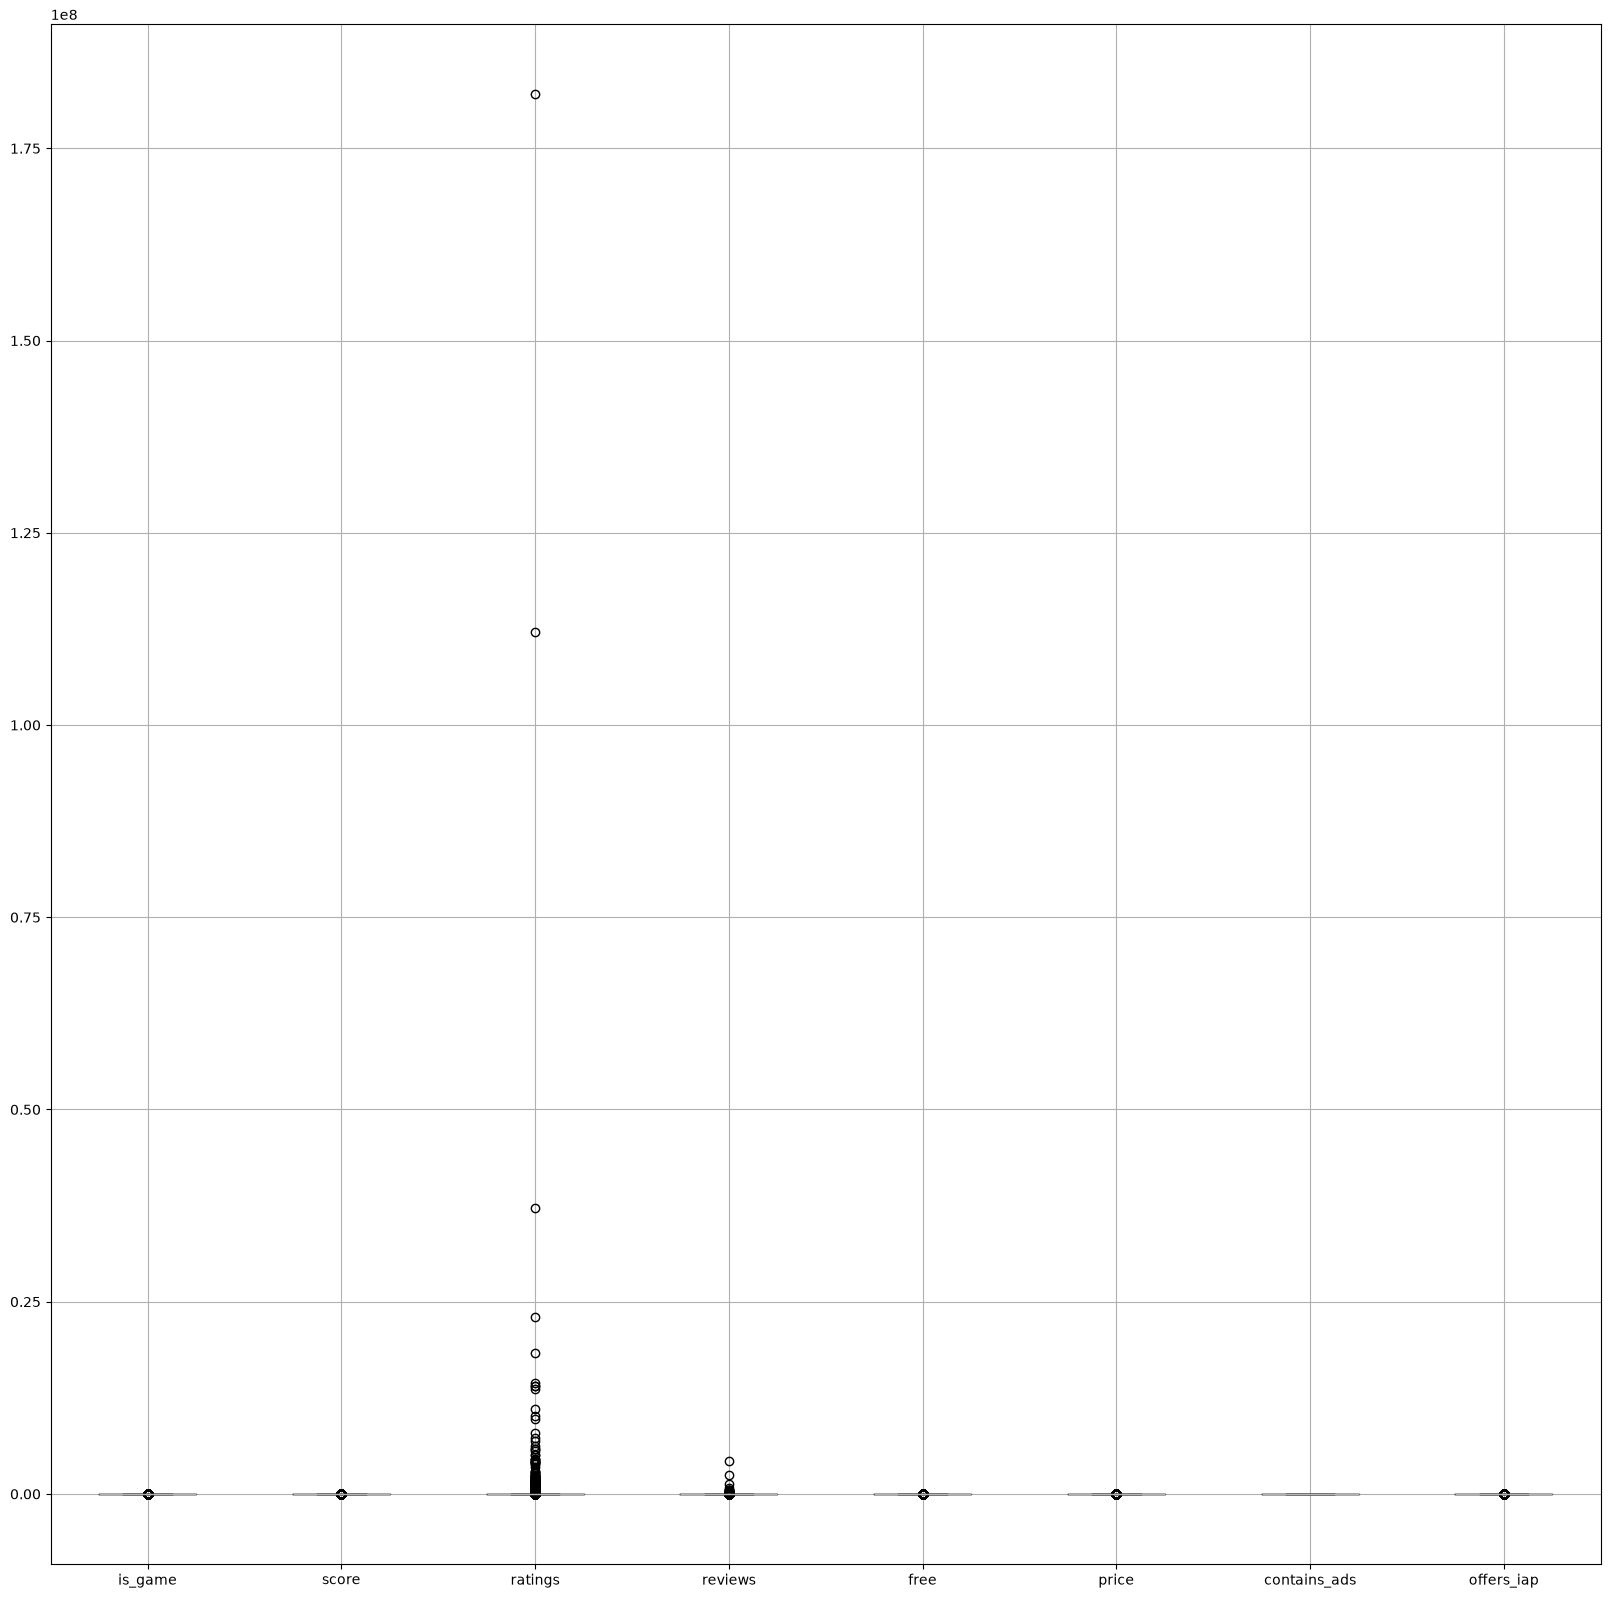

In [20]:
plt.figure(figsize=(20,20))
play_data.boxplot()
plt.show()

In [21]:
q1=play_data['ratings'].quantile(0.25)
q3=play_data['ratings'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
play_data['ratings']=play_data['ratings'].clip(upper,lower)

In [22]:
q1=play_data['reviews'].quantile(0.25)
q3=play_data['reviews'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
play_data['reviews']=play_data['reviews'].clip(upper,lower)

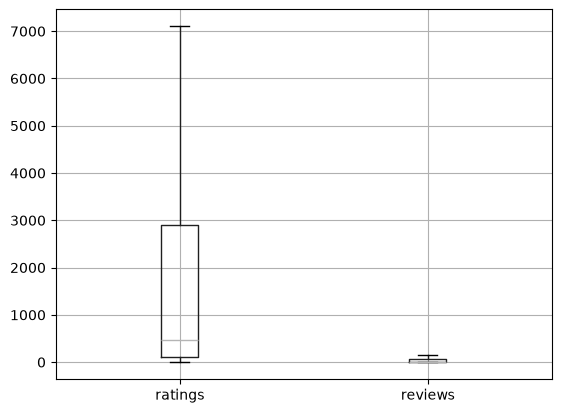

In [23]:
play_data.boxplot(column=['ratings','reviews'])
plt.show()

Successfully handled outlier Reviews

## Data Visualization

In [24]:
# Set a consistent plotting style
sns.set_theme(style="white", palette="tab10")

### Univariate analysis

In [25]:
rated_data.info()

<class 'pandas.DataFrame'>
Index: 31755 entries, 0 to 66500
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   developer       31755 non-null  str           
 1   genre           31755 non-null  str           
 2   is_game         31755 non-null  bool          
 3   installs        31755 non-null  str           
 4   score           31755 non-null  float64       
 5   ratings         31755 non-null  float64       
 6   reviews         31755 non-null  float64       
 7   free            31755 non-null  bool          
 8   price           31755 non-null  float64       
 9   contains_ads    31755 non-null  bool          
 10  offers_iap      31755 non-null  bool          
 11  content_rating  31755 non-null  str           
 12  last_updated    31755 non-null  datetime64[us]
 13  App Update Age  31755 non-null  int32         
dtypes: bool(4), datetime64[us](1), float64(4), int32(1), str(4)
memory usa

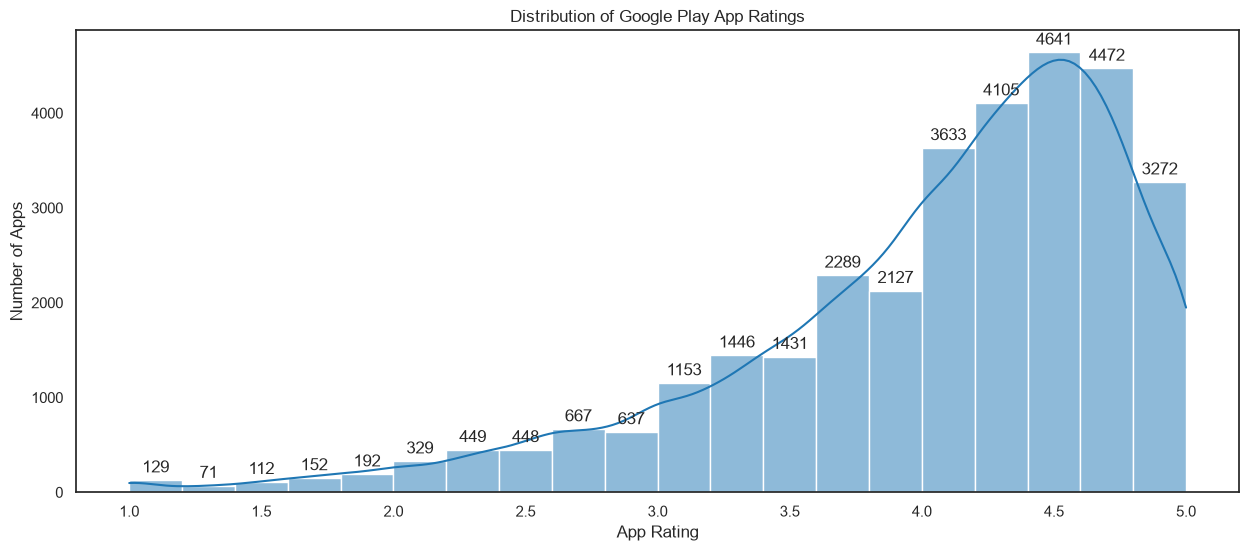

In [26]:
plt.figure(figsize=(15, 6))
ax=sns.histplot(
    data=rated_data,
    x='score',
    bins=20,
    kde=True
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Google Play App Ratings')
plt.xlabel('App Rating')
plt.ylabel('Number of Apps')
plt.show()

* Minimum rating : 1
* Maximum rating : 5
* Most of the applications got 4.5 rating - 4641
* Most of the ratings are between 4-5

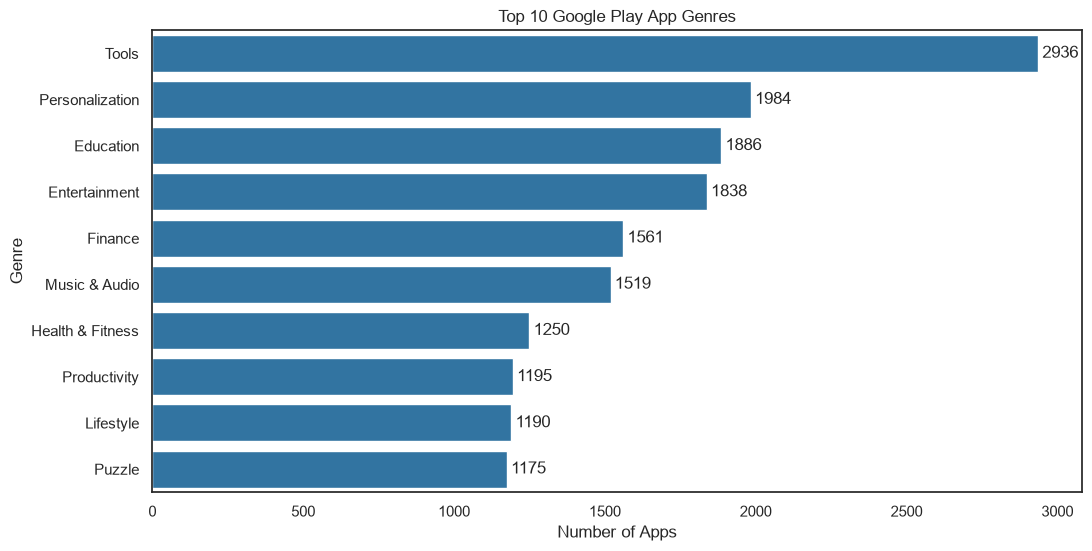

In [27]:
plt.figure(figsize=(12, 6))

order = rated_data['genre'].value_counts().head(10).index

ax=sns.countplot(
    data=rated_data,
    y='genre',
    order=order
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Top 10 Google Play App Genres')
plt.xlabel('Number of Apps')
plt.ylabel('Genre')
plt.show()

Tools has the highest number of apps, followed by Personalization and Education.

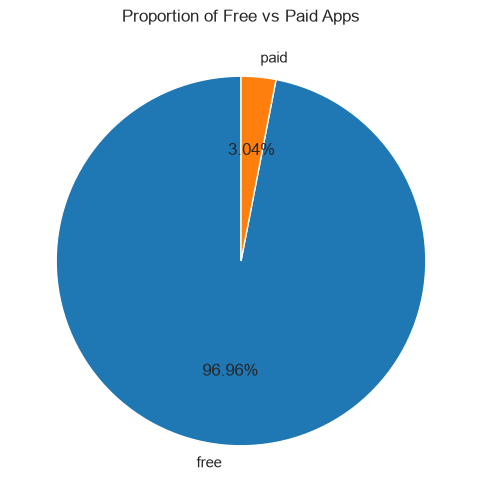

In [28]:
plt.figure(figsize=(6,6))

rated_data['free'].value_counts().rename({True: 'free', False: 'paid'}).sort_index().plot(
    kind='pie',
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Proportion of Free vs Paid Apps')
plt.show()

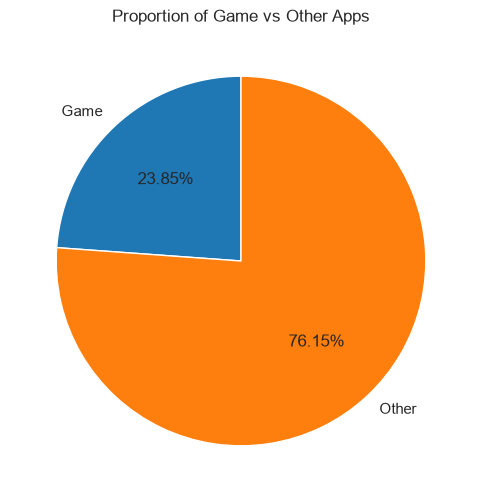

In [29]:
plt.figure(figsize=(6,6))

rated_data['is_game'].value_counts().rename({True: 'Game', False: 'Other'}).sort_index().plot(
    kind='pie',
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Proportion of Game vs Other Apps')
plt.show()

* Around 23.85% of the applications in playstore are games
* 76.15% of application includes others
* In shortly 1/4 of the playstore applications are games

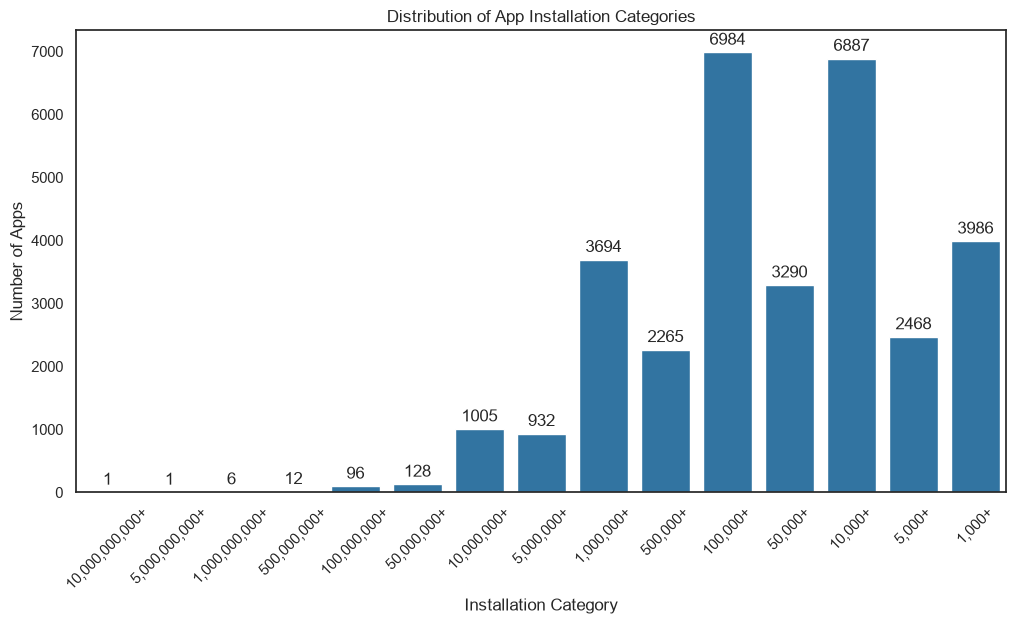

In [30]:
plt.figure(figsize=(12, 6))

order = rated_data['installs'].value_counts().head(10).index

ax=sns.countplot(
    data=rated_data,
    x='installs'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of App Installation Categories')
plt.xlabel('Installation Category')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.show()

* Limited number of applications got more than 5 Billion installations
* Most of the applications got installed between 10 thousand and 10 lakh

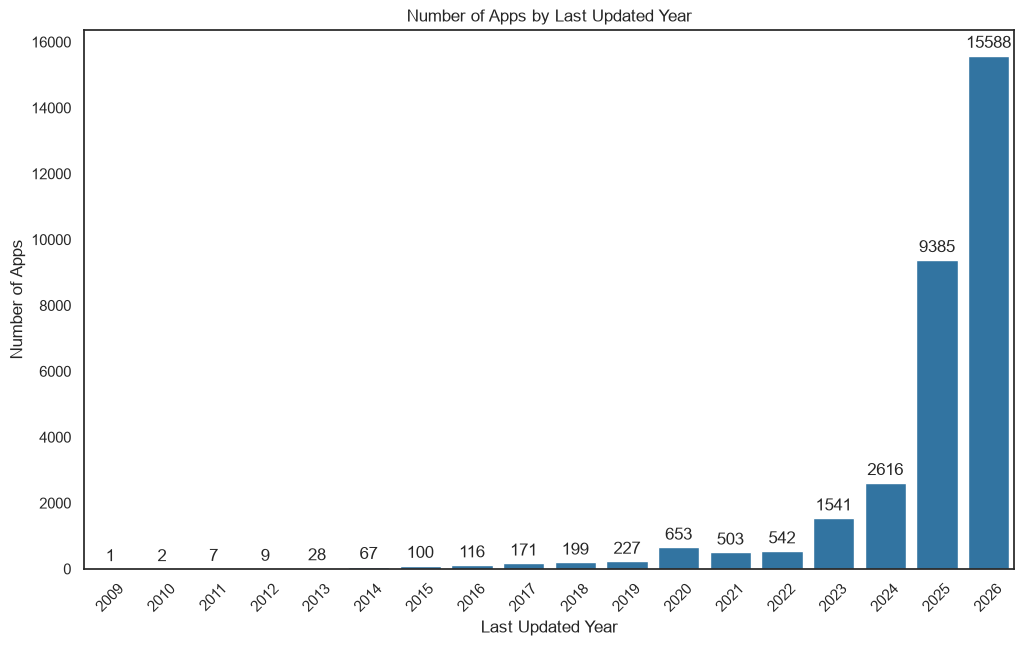

In [31]:
plt.figure(figsize=(12, 7))

ax=sns.countplot(
    data=rated_data,
    x=rated_data['last_updated'].dt.year
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Number of Apps by Last Updated Year')
plt.xlabel('Last Updated Year')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.show()

* Most of the applications are updated within 2026
* While comparing previous years, the rate of updation increases for last years

### Bivariate analysis

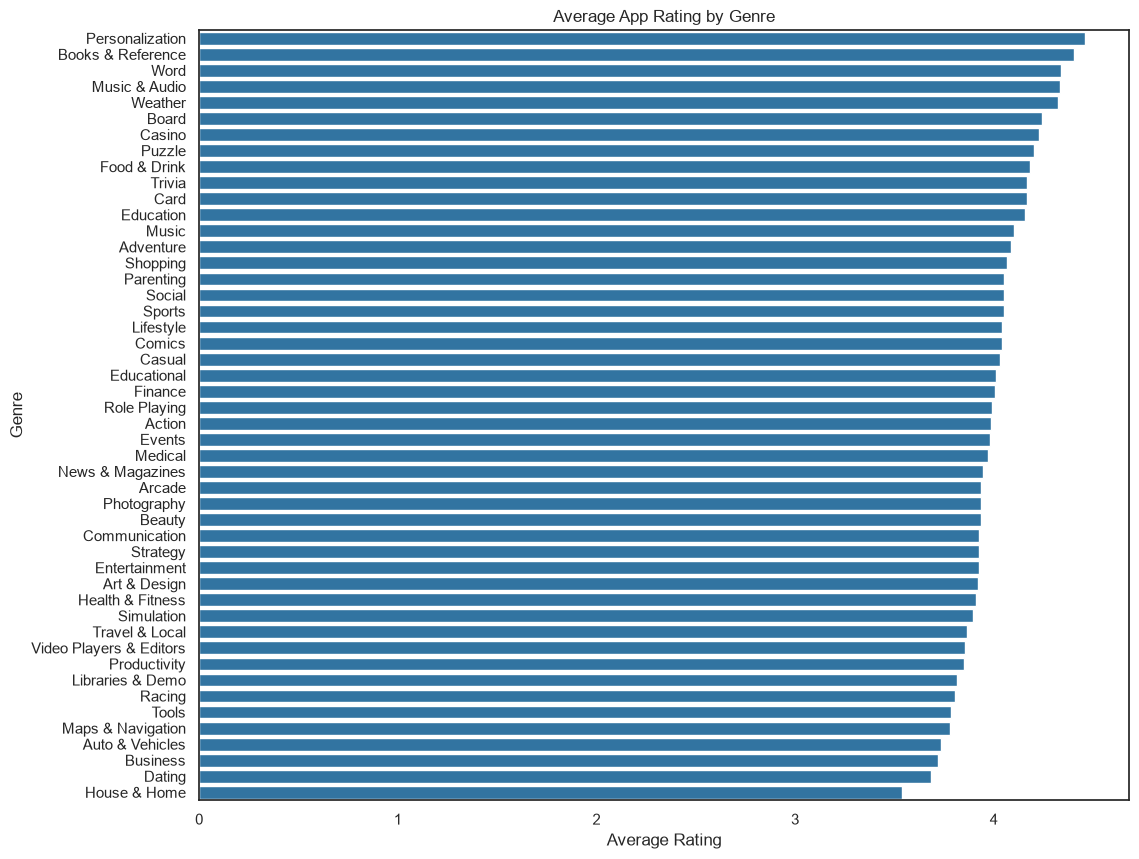

In [32]:
genre_rating = (
    rated_data.groupby('genre')['score']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 10))

sns.barplot(
    data=genre_rating,
    x='score',
    y='genre'
)

plt.title('Average App Rating by Genre')
plt.xlabel('Average Rating')
plt.ylabel('Genre')
plt.show()

* 'Personalisation' category shows highest average rating in the playstore application followed by Book and Reference' and 'Word'
* Most of the categories shows the average rating higher than 3.5
* 'Dating' and 'House & Home' categories shows lowest average ratings

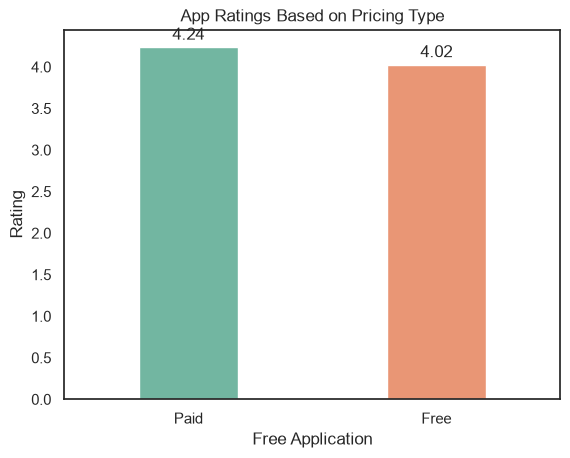

In [45]:
ax=sns.barplot(
    data=rated_data,
    x='free',
    y='score',
    errorbar=None,
    width=0.4,               
    palette='Set2',        
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('App Ratings Based on Pricing Type')
plt.xlabel('Free Application')
plt.ylabel('Rating')
plt.xticks([0, 1], ['Paid', 'Free'])
plt.show()

* Paid applications : 4.24
* Free applications : 4.02
* Paid application shows higher rating than free appliccations

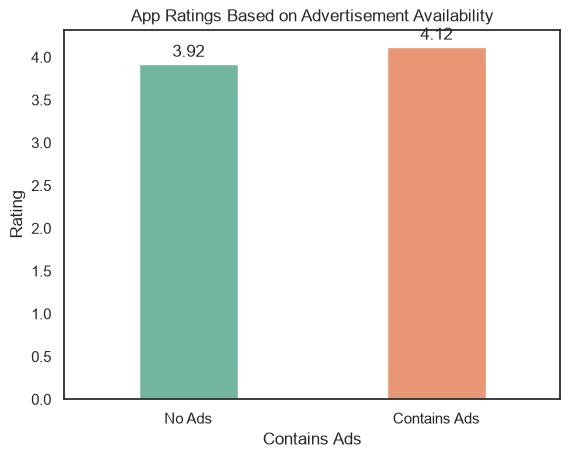

In [46]:
ax=sns.barplot(
    data=rated_data,
    x='contains_ads',
    y='score',
    errorbar=None,
    width=0.4,               
    palette='Set2',        
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('App Ratings Based on Advertisement Availability')
plt.xlabel('Contains Ads')
plt.ylabel('Rating')
plt.xticks([0, 1], ['No Ads', 'Contains Ads'])
plt.show()

* Applications contains ads have higher rating of 4.12
* Applications without ads have rating of 3.92
* Application contain ads shows higher rating than application with no ads. That is good quality or higher rated applications contains ads

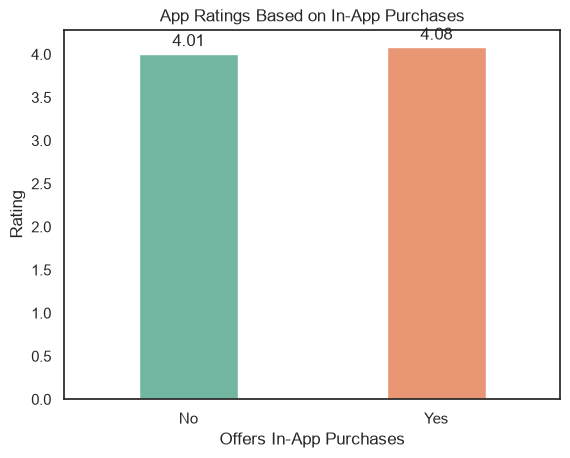

In [47]:
ax=sns.barplot(
    data=rated_data,
    x='offers_iap',
    y='score',
    errorbar=None,
    width=0.4,               
    palette='Set2',        
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('App Ratings Based on In-App Purchases')
plt.xlabel('Offers In-App Purchases')
plt.ylabel('Rating')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

* Application with In-App Purchase shows rating of 4.08
* Application without In-App Purchase shows rating of 4.01
* It shows a small difference of 0.07
* Peoples are interested more in In-App Purchase applications

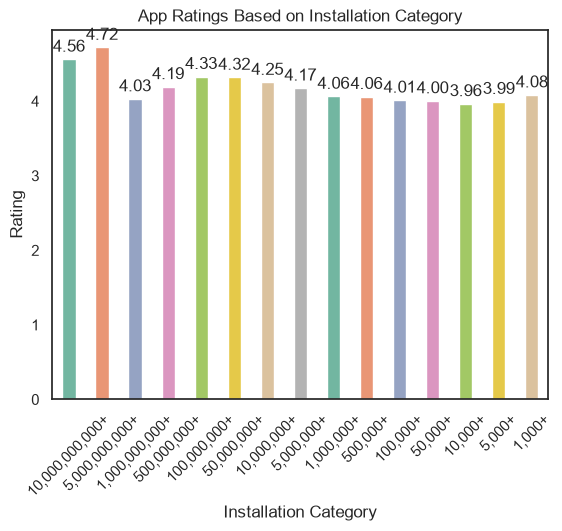

In [48]:
ax=sns.barplot(
    data=rated_data,
    x='installs',
    y='score',
    errorbar=None,
    width=0.4,               
    palette='Set2',        
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('App Ratings Based on Installation Category')
plt.xlabel('Installation Category')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.show()

* Higher rating increases the installation
* Most installed applications got higher ratings


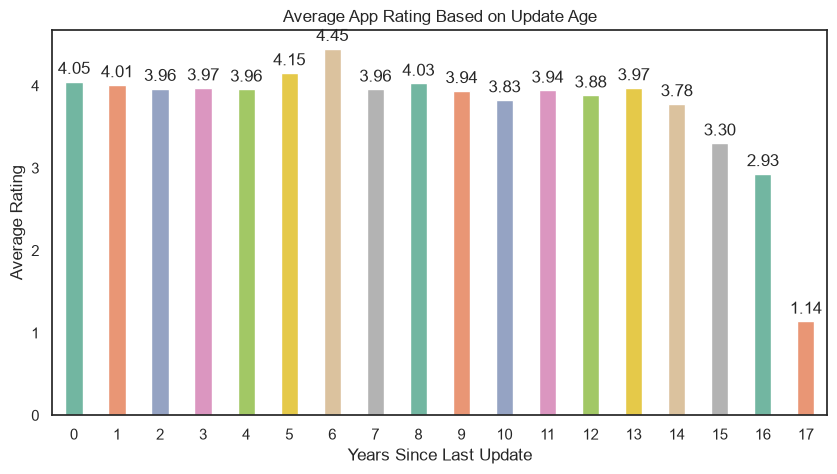

In [50]:
plt.figure(figsize=(10, 5))
ax=sns.barplot(
    data=rated_data,
    x='App Update Age',
    y='score',
    errorbar=None,
    width=0.4,               
    palette='Set2',        
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('Average App Rating Based on Update Age')
plt.xlabel('Years Since Last Update')
plt.ylabel('Average Rating')
plt.show()

* Recently updated apps have an average rating of approximately 4.05
* The relationship is not consistently decreasing with update age.
* Some shows higher rating than the recent even the last update is 6years before

### Multivariate analysis

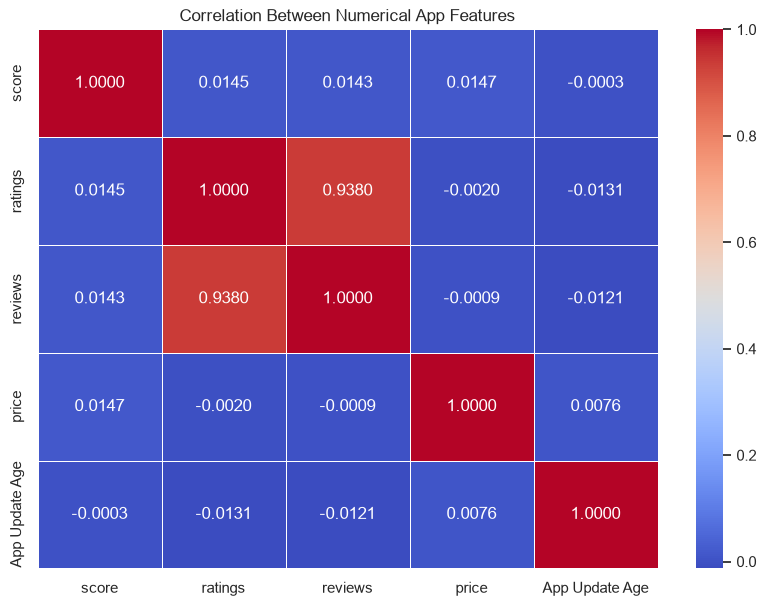

In [53]:
plt.figure(figsize=(10, 7))

corr = rated_data[
    [
        'score',
        'ratings',
        'reviews',
        'price',
        'App Update Age'
    ]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical App Features')
plt.show()

* The strongest relationship is between ratings and reviews, with a correlation of 0.9380.
* Average app rating (score) has almost no linear correlation with ratings count, reviews count, price, or update age.
* 

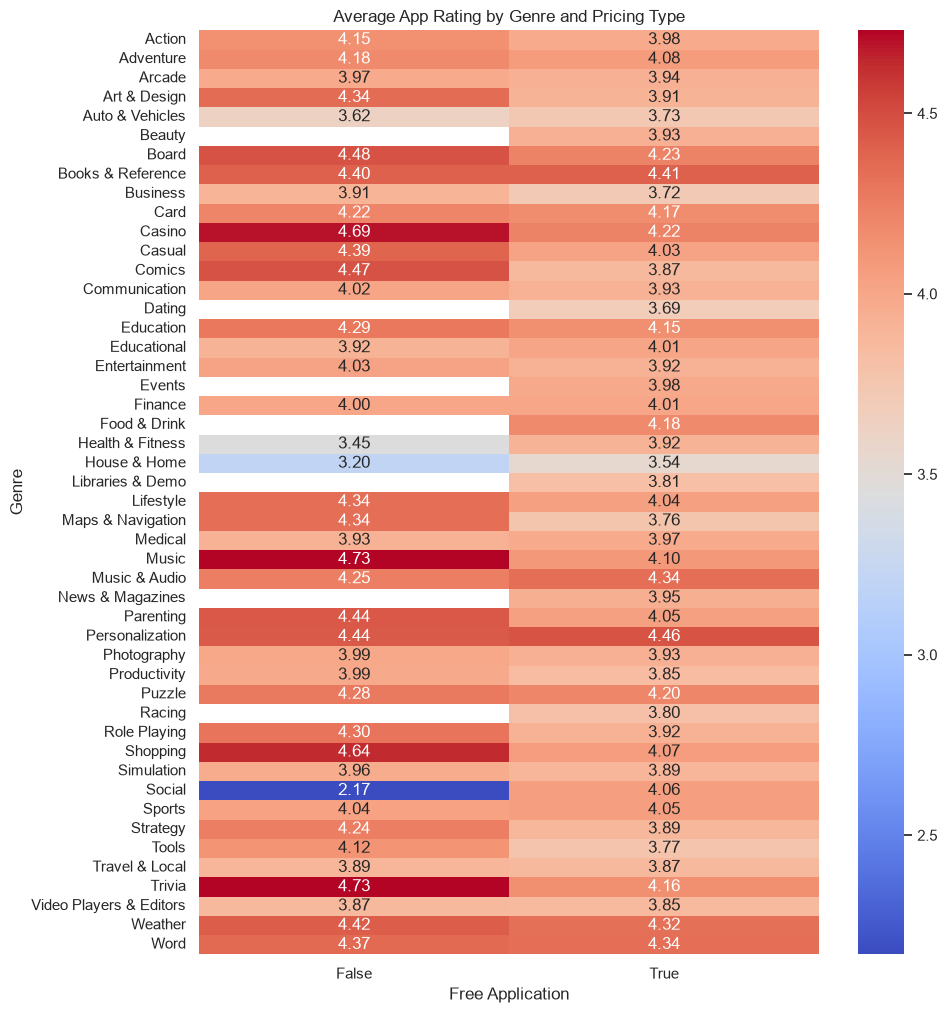

In [59]:
pivot_data = rated_data.pivot_table(
    index='genre',
    columns='free',
    values='score',
    aggfunc='mean'
)

plt.figure(figsize=(10, 12))

sns.heatmap(
    pivot_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Average App Rating by Genre and Pricing Type')
plt.xlabel('Free Application')
plt.ylabel('Genre')
plt.show()

* Paid Casino, Shopping, and Communication apps have higher average ratings than their free counterparts.
* Free Social apps have a considerably higher average rating than paid Social apps.
* Personalization and Books & Reference apps have nearly identical ratings across both pricing types.
* The difference between free and paid ratings varies depending on the genre

## Conclusion

* Most Play Store apps have ratings between 4.0 and 5.0, indicating generally positive user feedback.
* Tools, Personalization, and Education have the highest number of applications.
* Approximately 76.15% of apps are non-gaming applications, while 23.85% are games.
* Most applications fall within the 10K to 1M installation range.
* Personalization has the highest average rating among app genres.
* Paid apps (4.24) have higher average ratings than free apps (4.02).
* Apps with advertisements have higher average ratings than apps without advertisements.
* The difference in ratings between free and paid apps varies across genres.